# SWYNEX Task 2: Exploratory Data Analysis
### What separates customers who churn from those who stay?

**Author:** Karthik · **Programme:** SWYNEX Technologies Data Science Internship · **Input:** `data/processed/telco_churn_clean.csv` (Task 1 output)

**Goal:** understand the churn target, find the strongest signals, check them statistically, and turn them into decisions for modeling (Task 3) and for the business.

In [1]:
import warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED = "#2b6cb0", "#c53030"

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
def savefig(name): plt.savefig(FIG / name, bbox_inches="tight")

df = pd.read_csv(ROOT / "data" / "processed" / "telco_churn_clean.csv")
df["contract"] = pd.Categorical(df["contract"], ["Month-to-month", "One year", "Two year"], ordered=True)
print(df.shape)
df.head()

(7043, 21)


,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
0,7590-VHVEG,Female,0,1,0,1,0,0,DSL,0,...,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,0,0,34,1,0,DSL,1,...,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,0,0,2,1,0,DSL,1,...,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,0,0,45,0,0,DSL,1,...,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,0,0,2,1,0,Fiber optic,0,...,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1


## 1. The target: how many customers churn?

In [2]:
churn_rate = df["churn"].mean()
print(f"Churned: {df['churn'].sum():,} of {len(df):,} customers ({churn_rate:.1%})")
print(f"Retained: {(df['churn']==0).sum():,} ({1-churn_rate:.1%})")

Churned: 1,869 of 7,043 customers (26.5%)
Retained: 5,174 (73.5%)


About one customer in four churns. The classes are moderately imbalanced, so a model that predicts "no churn" for everyone would score ~73.5% accuracy while being useless. This is why Task 3 uses PR-AUC and recall instead of accuracy, and stratified splits.

## 2. Numeric features: tenure, monthly charges, total charges

tenure        monthly_charges        total_charges        
          mean median            mean median          mean  median
Stayed    37.6   38.0            61.3   64.4        2549.9  1679.5
Churned   18.0   10.0            74.4   79.6        1531.8   703.6

Mann-Whitney U p-values (churned vs stayed): {'tenure': '2.4e-208', 'monthly_charges': '3.3e-54', 'total_charges': '5.7e-83'}


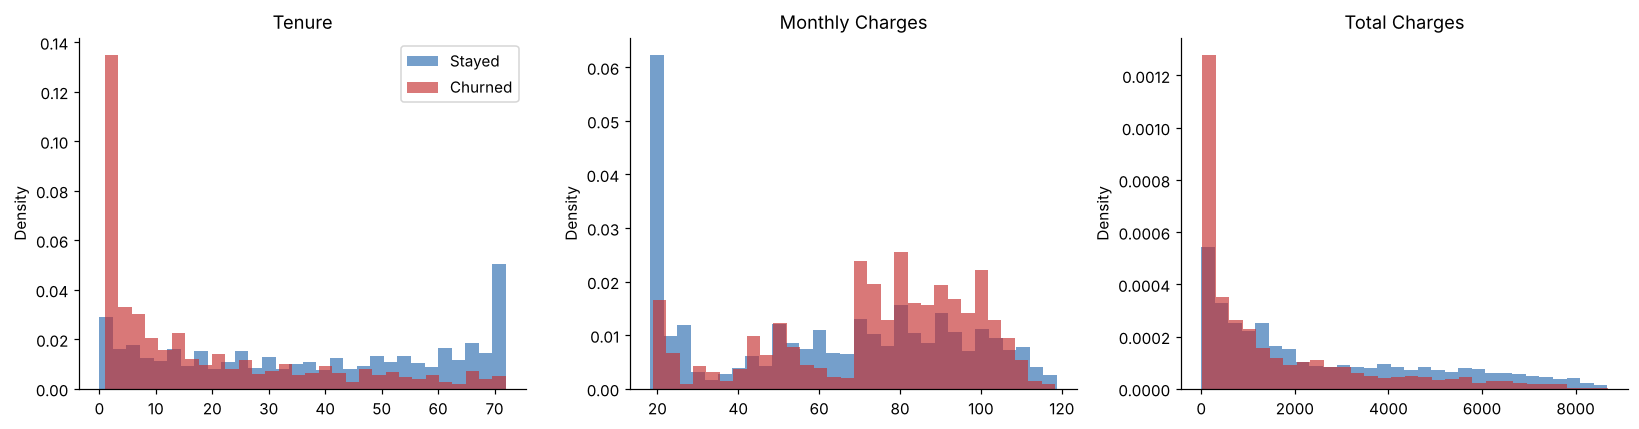

In [3]:
num = ["tenure", "monthly_charges", "total_charges"]
summary = df.groupby("churn")[num].agg(["mean", "median"]).round(1)
summary.index = ["Stayed", "Churned"]
display(summary)

mw = {c: stats.mannwhitneyu(df.loc[df.churn == 1, c], df.loc[df.churn == 0, c]).pvalue for c in num}
print("Mann-Whitney U p-values (churned vs stayed):", {k: f"{v:.1e}" for k, v in mw.items()})

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, num):
    a.hist(df.loc[df.churn == 0, c], bins=30, alpha=.65, color=BLUE, label="Stayed", density=True)
    a.hist(df.loc[df.churn == 1, c], bins=30, alpha=.65, color=RED, label="Churned", density=True)
    a.set_title(c.replace("_", " ").title()); a.set_ylabel("Density")
ax[0].legend(); plt.tight_layout(); savefig("eda_01_numeric_distributions.png"); plt.show()

Churners are **newer** (median tenure 10 vs 38 months) and **pay more per month** (median 79.65 vs 64.43). Their *total* charges are lower only because they have been customers for less time. All three differences are highly significant (p < 1e-50), but tenure is by far the strongest.

## 3. Churn by tenure band

,rate,customers
tenure_band,,
0-12,47.4,2186
13-24,28.7,1024
25-48,20.4,1594
49-72,9.5,2239


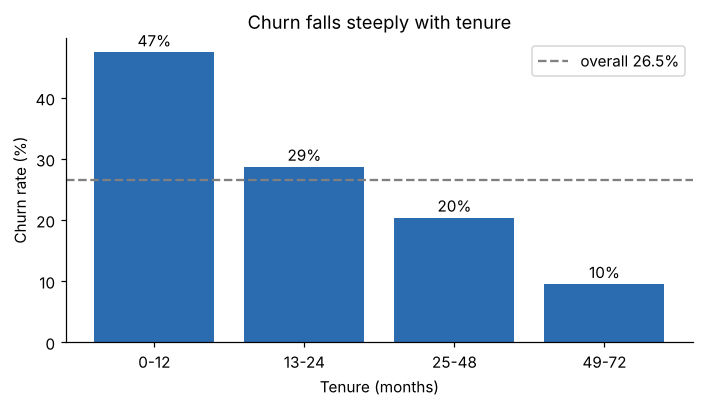

Share of all churners who leave within their first 12 months: 55.5%


In [4]:
df["tenure_band"] = pd.cut(df["tenure"], [-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
tb = df.groupby("tenure_band", observed=True)["churn"].agg(rate="mean", customers="size")
display(tb.assign(rate=(tb.rate * 100).round(1)))

plt.figure(figsize=(6.5, 3.8))
plt.bar(tb.index.astype(str), tb.rate * 100, color=BLUE)
plt.axhline(churn_rate * 100, ls="--", c="grey", label=f"overall {churn_rate:.1%}")
for i, v in enumerate(tb.rate * 100): plt.text(i, v + 1, f"{v:.0f}%", ha="center")
plt.xlabel("Tenure (months)"); plt.ylabel("Churn rate (%)"); plt.title("Churn falls steeply with tenure"); plt.legend()
plt.tight_layout(); savefig("eda_02_churn_by_tenure_band.png"); plt.show()

first_year_share = (df.loc[df.churn == 1, "tenure"] <= 12).mean()
print(f"Share of all churners who leave within their first 12 months: {first_year_share:.1%}")

Nearly half (47%) of customers in their first year churn, versus under 10% after four years, and **55% of all churners leave within 12 months**. Early-life retention is the biggest lever.

## 4. Categorical drivers

In [5]:
cats = ["contract", "internet_service", "payment_method", "paperless_billing", "senior_citizen",
        "partner", "dependents", "tech_support", "online_security", "gender", "phone_service"]

rows = []
for c in cats:
    t = pd.crosstab(df[c], df["churn"])
    chi2, p, _, _ = stats.chi2_contingency(t)
    v = np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))
    hi, lo = df.groupby(c, observed=True)["churn"].mean().agg(["max", "min"])
    rows.append({"feature": c, "Cramér's V": round(v, 3), "p-value": f"{p:.1e}",
                 "highest-group churn": f"{hi:.1%}", "lowest-group churn": f"{lo:.1%}"})
assoc = pd.DataFrame(rows).sort_values("Cramér's V", ascending=False).set_index("feature")
assoc

,Cramér's V,p-value,highest-group churn,lowest-group churn
feature,,,,
contract,0.410,5.9e-258,42.7%,2.8%
internet_service,0.322,9.6e-160,41.9%,7.4%
payment_method,0.303,3.7e-140,45.3%,15.2%
paperless_billing,0.191,4.1e-58,33.6%,16.3%
online_security,0.171,1.2e-46,31.3%,14.6%
tech_support,0.164,2.9e-43,31.2%,15.2%
dependents,0.164,4.9e-43,31.3%,15.5%
partner,0.150,2.1e-36,33.0%,19.7%
senior_citizen,0.150,1.5e-36,41.7%,23.6%


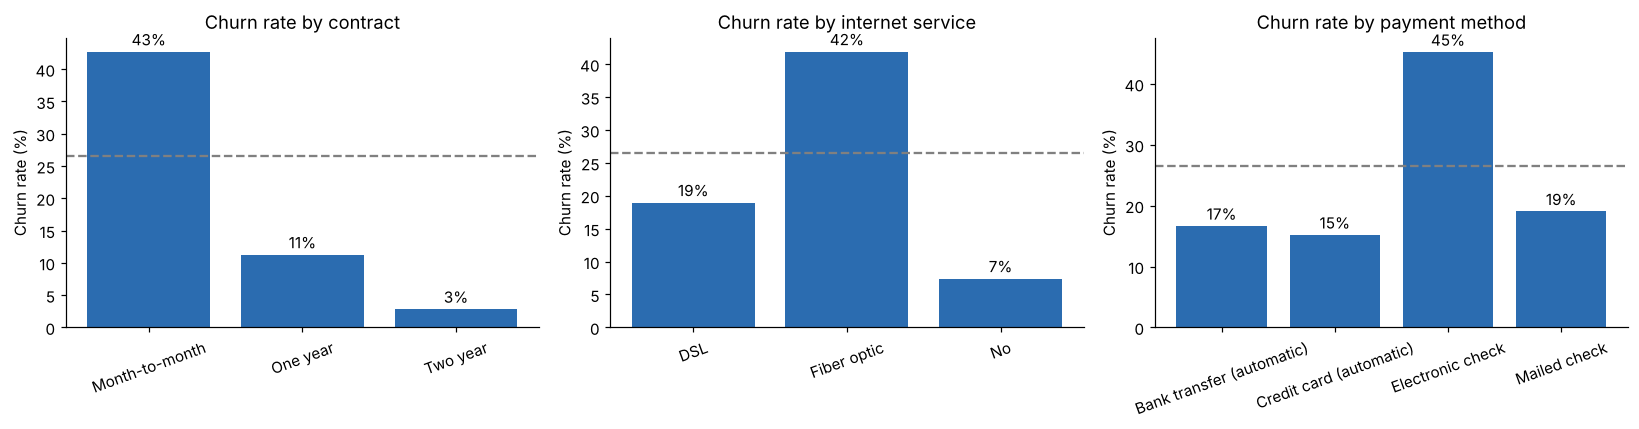

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["contract", "internet_service", "payment_method"]):
    r = df.groupby(c, observed=True)["churn"].mean() * 100
    a.bar(r.index.astype(str), r.values, color=BLUE)
    a.axhline(churn_rate * 100, ls="--", c="grey")
    for i, v in enumerate(r.values): a.text(i, v + 1, f"{v:.0f}%", ha="center")
    a.set_title(f"Churn rate by {c.replace('_', ' ')}"); a.set_ylabel("Churn rate (%)")
    a.tick_params(axis="x", rotation=20)
plt.tight_layout(); savefig("eda_03_churn_by_category.png"); plt.show()

**Strongest signals** (by Cramér's V): contract type (V=0.41), internet service (0.32), payment method (0.30), then paperless billing, online security, tech support, senior citizen, dependents and partner (all 0.15–0.19).

**No signal:** `gender` (26.9% vs 26.2%, p=0.49) and `phone_service` (p=0.34). Gender differences are statistically indistinguishable from chance, which is also reassuring from a fairness standpoint.

## 5. Services and support add-ons

,Without add-on,With add-on,difference (pts)
online security,41.8,14.6,-27.2
tech support,41.6,15.2,-26.5
online backup,39.9,21.5,-18.4
device protection,39.1,22.5,-16.6
streaming movies,33.7,29.9,-3.7
streaming tv,33.5,30.1,-3.5


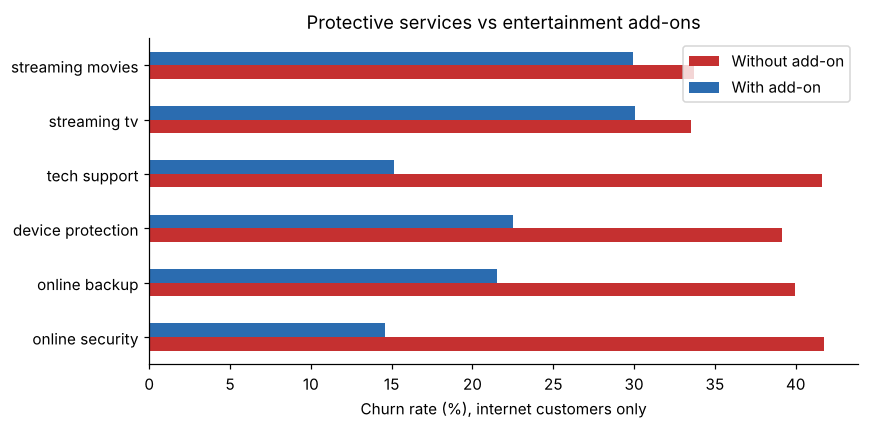

In [7]:
inet = df[df["internet_service"] != "No"].copy()
addons = ["online_security", "online_backup", "device_protection", "tech_support", "streaming_tv", "streaming_movies"]
tab = pd.DataFrame({a.replace("_", " "): inet.groupby(a)["churn"].mean() * 100 for a in addons}).T
tab.columns = ["Without add-on", "With add-on"]
tab["difference (pts)"] = tab["With add-on"] - tab["Without add-on"]
display(tab.round(1).sort_values("difference (pts)"))

tab[["Without add-on", "With add-on"]].plot.barh(figsize=(8, 4), color=[RED, BLUE])
plt.xlabel("Churn rate (%), internet customers only"); plt.title("Protective services vs entertainment add-ons")
plt.tight_layout(); savefig("eda_04_addons.png"); plt.show()

The comparison is restricted to internet customers, because customers with no internet have no add-ons *and* very low churn, which would otherwise distort the result. **Online security and tech support** show the largest gaps (about 27 points lower churn: 14.6% vs 41.8%, and 15.2% vs 41.6%), followed by backup and device protection (17-18 points). **Streaming** add-ons barely matter (3-4 points). These are associations, not proof of cause: customers who buy security and support may simply be more engaged.

## 6. Interactions: contract x internet service

internet_service,DSL,Fiber optic,No
contract,,,
Month-to-month,32.2,54.6,18.9
One year,9.3,19.3,2.5
Two year,1.9,7.2,0.8



Average monthly charge by internet service:


,avg monthly charge ($)
internet_service,
DSL,58.1
Fiber optic,91.5
No,21.1


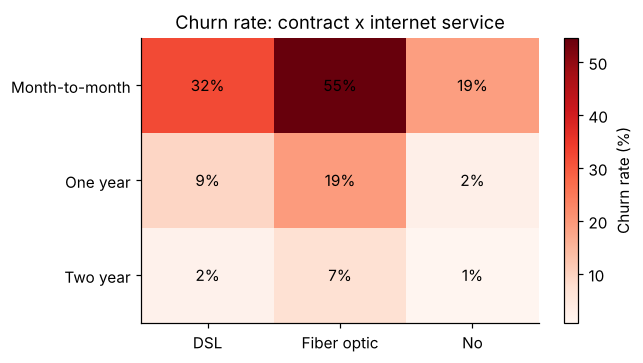

High-risk profile (month-to-month + fiber + electronic check): 1,307 customers (18.6%), churn 60.4% vs 18.8% for everyone else; captures 42% of all churners


In [8]:
pv = pd.crosstab(df["contract"], df["internet_service"], values=df["churn"], aggfunc="mean") * 100
display(pv.round(1))
print("\nAverage monthly charge by internet service:")
display(df.groupby("internet_service")["monthly_charges"].mean().round(1).to_frame("avg monthly charge ($)"))

import matplotlib.colors as mc
plt.figure(figsize=(6, 3.4))
plt.imshow(pv.values, cmap="Reds", aspect="auto")
plt.xticks(range(3), pv.columns); plt.yticks(range(3), pv.index)
for i in range(3):
    for j in range(3): plt.text(j, i, f"{pv.values[i, j]:.0f}%", ha="center", va="center")
plt.colorbar(label="Churn rate (%)"); plt.title("Churn rate: contract x internet service")
plt.tight_layout(); savefig("eda_05_contract_internet_heatmap.png"); plt.show()

risk = (df.contract == "Month-to-month") & (df.internet_service == "Fiber optic") & (df.payment_method == "Electronic check")
print(f"High-risk profile (month-to-month + fiber + electronic check): {risk.sum():,} customers "
      f"({risk.mean():.1%}), churn {df.loc[risk,'churn'].mean():.1%} vs {df.loc[~risk,'churn'].mean():.1%} for everyone else; "
      f"captures {df.loc[risk,'churn'].sum()/df['churn'].sum():.0%} of all churners")

Fiber customers churn at **42%** (vs 19% DSL) and pay the most ($91.5/month on average), but the effect is concentrated in the month-to-month group (**55%**). On a two-year contract even fiber customers churn at only 7%. The combination of month-to-month, fiber and electronic check defines a segment of ~1,300 customers (18.6% of the base) with **60% churn**, accounting for **42% of all churners**.

## 7. Correlation among numeric and binary features

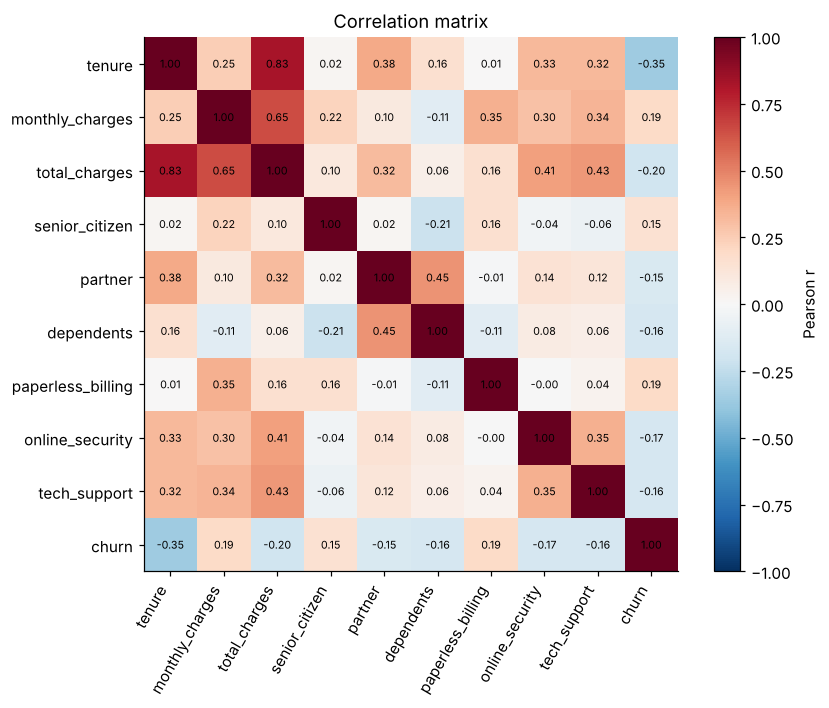

Correlation of tenure with total_charges: 0.826
Correlation of churn with tenure: -0.352


In [9]:
corr_cols = ["tenure", "monthly_charges", "total_charges", "senior_citizen", "partner", "dependents",
             "paperless_billing", "online_security", "tech_support", "churn"]
corr = df[corr_cols].corr()
plt.figure(figsize=(8, 6.5))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(corr_cols)), corr_cols, rotation=60, ha="right"); plt.yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)): plt.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(label="Pearson r"); plt.title("Correlation matrix"); plt.tight_layout(); savefig("eda_06_correlation.png"); plt.show()
print("Correlation of tenure with total_charges:", round(df.tenure.corr(df.total_charges), 3))
print("Correlation of churn with tenure:", round(df.tenure.corr(df.churn), 3))

`tenure` and `total_charges` are strongly correlated (r=0.83) because total charges accumulate over time. Tree-based models handle this well; for linear models it is a multicollinearity risk, which Task 3 addresses with regularisation. Churn correlates most with tenure (r = -0.35).

## 8. Data-quality notes carried from Task 1

In [10]:
dups = int(df.drop(columns="customer_id").duplicated().sum())
print(f"Rows identical on every feature except customer_id: {dups} (kept: distinct customers can share a profile)")

Rows identical on every feature except customer_id: 22 (kept: distinct customers can share a profile)


## 9. Summary of findings and implications

| # | Finding | Evidence | Implication |
|---|---|---|---|
| 1 | Contract type is the strongest driver | Month-to-month 42.7% vs two-year 2.8% churn | Incentivise contract upgrades |
| 2 | Churn is front-loaded | 47% churn in year 1; 55% of churners leave within 12 months | Invest in onboarding and early check-ins |
| 3 | Fiber optic customers churn most | 41.9% vs 19.0% DSL, despite the highest bills | Review fiber pricing, reliability, and value perception |
| 4 | Electronic-check payers churn most | 45.3% vs ~15-19% for other methods | Move customers to automatic payments |
| 5 | Security and tech support go with much lower churn | About 27 pts lower among internet customers (association, not proof of cause) | Bundle or promote these services; test with an A/B pilot |
| 6 | Gender and phone service carry no signal | p = 0.49 and 0.34 | No need to target by gender |
| 7 | A 1,300-customer high-risk segment exists | 60% churn, 42% of all churners | Priority group for retention offers |

**Implications for modeling (Task 3):** use stratified splits, PR-AUC and recall; expect contract, tenure and charges to dominate; handle the tenure/total-charges correlation; and engineer an add-on count feature.